# Splats and scans: view, build, composite

One notebook for the whole splat path, in three parts:

1. **Viewing splats**: orbit, zoom and pan any Gaussian-splat `.ply` (`hurobo.utils.viewer`).
2. **Scan pipeline**: orbit video to posed cameras, object frame, and the best scans (`hurobo.scan`, `hurobo.best_scans`).
3. **Compositing into LIBERO**: splats replace the appearance of simulator bodies (`hurobo.splat.SplatCompositor`).

Part 3 needs a CUDA GPU (gsplat) and EGL.

In [ ]:
%load_ext autoreload
%autoreload 2

In [1]:
from hurobo.utils.notebook import setup_notebook

ROOT = setup_notebook()  # chdir to the repo root and set MUJOCO_GL=egl; must precede any mujoco import

# Part 1: 3D splat viewer (interactive)

Orbit, zoom and pan any Gaussian-splat `.ply` the workspace produces or consumes.

- **Module:** `hurobo.utils.viewer` (`splat_figure`, `load_splat_points`, `orbit_figure`), `hurobo.splat.render_splat_orbit`
- **Produced by:** `scripts/09_scan_object.py` (own scans) or downloaded DISCOVERSE assets
- **Consumed by:** `hurobo.splat.SplatCompositor` (see Part 3)

Each point is one Gaussian centre, coloured by its base (SH degree-0) colour. This is a *point* view for inspection: the *rendered* orbit views further down draw the full Gaussians (extent, orientation, opacity) so the object's shape is visible. Neither shows view-dependent shading; use Part 3 for renders in the sim scene.

In [2]:
from hurobo.utils.notebook import existing_paths
from hurobo.utils.viewer import splat_figure, splat_statistics

SPLATS = existing_paths(
    {
        "bowl": ROOT / "data/splats/bowl.ply",
        "scanned fruit bowl (own SfM+3DGS)": ROOT / "data/splats/dummy_fruit_bowl.ply",
        "DISCOVERSE pink bowl": ROOT / "data/splats/dummy_discoverse/object__bowl_pink.ply",
        "DISCOVERSE white plate": ROOT / "data/splats/dummy_discoverse/object__plate_white.ply",
        "DISCOVERSE table cloth": ROOT / "data/splats/dummy_discoverse/object__table_cloth_0.ply",
    },
    "run scripts/09_scan_object.py or scripts/08_splat_composite.py first",
)

## Interactive view
Use the dropdown (top-left) to switch splat. Drag to orbit, scroll to zoom.

In [3]:
splat_figure(SPLATS, max_points=15_000, title="Gaussian splat centres, coloured by base colour").show()

## Size of each splat
Extent is in the splat's own frame; scanned splats are SfM-scale (arbitrary) until aligned with a ChArUco board.

In [4]:
splat_statistics(SPLATS)

,splat,gaussians,opaque (>0.1),extent x,extent y,extent z
0,bowl,106418,71502,14.079,13.985,6.437
1,scanned fruit bowl (own SfM+3DGS),93602,40309,1.877,1.953,1.455
2,DISCOVERSE pink bowl,155885,150762,0.121,0.121,0.049
3,DISCOVERSE white plate,34728,32990,0.141,0.141,0.017
4,DISCOVERSE table cloth,106151,94730,1.332,0.705,0.363


## Rendered splats
The centres above are a sparse point cloud. Here each splat is rasterised with gsplat (full anisotropic Gaussians) from cameras orbiting its centre, so the surface shape shows. Drag the slider to orbit. Floaters and spiky Gaussians in a scan are real: they are what the optimiser produced.

In [5]:
from hurobo.splat import render_splat_orbit
from hurobo.utils.viewer import orbit_figure

for name, path in SPLATS.items():
    orbit_figure(render_splat_orbit(path), title=f"Rendered splat: {name}").show()

# Part 2: Scan pipeline, orbit video to posed cameras

What `scripts/09_scan_object.py` does before splat training: keyframes, COLMAP SfM, and the object frame.

- **Modules:** `hurobo.scan` (`KeyframeSampler`, `SfmReconstructor`, `object_frame_from_orbit`), `hurobo.splat` (`render_splat_orbit`), `hurobo.utils.viewer`
- **Data:** the committed-by-script outputs of the dummy fruit-bowl clip under `data/scans/dummy_fruit_bowl/`

This notebook only *reads* the finished reconstruction (fast). To redo it:
`uv run python scripts/09_scan_object.py data/raw/dummy_orbits/<clip>.mp4 --name dummy_fruit_bowl`

In [6]:
import numpy as np

from hurobo.scan import largest_model, load_sparse_models, object_frame_from_orbit, sfm_result_from_model
from hurobo.utils.plotting import plot_image_row
from hurobo.utils.viewer import sfm_figure

SCAN_DIR = ROOT / "data/scans/bowl"  # bowl | dummy_fruit_bowl
models = load_sparse_models(SCAN_DIR / "colmap/sparse")
model = largest_model(models)  # same choice SfmReconstructor makes
print(
    f"{len(models)} sub-model(s); largest: {model.num_reg_images()} images, "
    f"{model.num_points3D():,} points, "
    f"mean reprojection error {model.compute_mean_reprojection_error():.2f} px"
)
sfm = sfm_result_from_model(model)  # poses and points only; no pixels needed for this notebook

1 sub-model(s); largest: 7 images, 349 points, mean reprojection error 0.32 px


## Cameras and sparse points in the SfM frame
The SfM frame is arbitrary in position, orientation and scale. Red pyramids are the registered keyframes.

In [7]:
sfm_figure(
    sfm.points_world, sfm.colors, sfm.t_world_cam_list, title="SfM frame: sparse points + keyframe cameras"
).show()

## Object frame from the orbit
`object_frame_from_orbit` finds the orbit plane (camera centres) and makes its normal +z, with the base at z=0. Afterwards the object sits upright on the origin, which is what `SplatFit.MATCH_BODY_XY` assumes.

In [8]:
sfm_obj = sfm.in_frame(object_frame_from_orbit(sfm))

sfm_figure(
    sfm_obj.points_world,
    sfm_obj.colors,
    sfm_obj.t_world_cam_list,
    title="Object frame: z up the orbit axis, base at z=0",
).show()
z_obj = sfm_obj.points_world[:, 2]
print(
    f"object-frame z range of sparse points: {np.percentile(z_obj, 2):.3f} .. {np.percentile(z_obj, 98):.3f}"
)

object-frame z range of sparse points: -0.000 .. 4.878


## Photo vs splat
Held-out-style check written by the script: the real keyframe next to the trained splat rendered from the same pose.

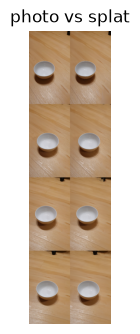

In [9]:
import matplotlib.pyplot as plt

plot_image_row({"photo vs splat": plt.imread(SCAN_DIR / "preview_photo_vs_splat.png")}, height_in=4)

## Rendered splat
The trained splat rasterised from cameras orbiting its centre (full Gaussians, not just centres), to inspect the 3D shape the scan produced. Drag the slider to orbit.

In [10]:
from hurobo.splat import render_splat_orbit
from hurobo.utils.viewer import orbit_figure

SPLAT_PLY = ROOT / "data/splats" / f"{SCAN_DIR.name}.ply"
orbit_figure(render_splat_orbit(SPLAT_PLY), title=f"Rendered splat: {SCAN_DIR.name}").show()

## The best scans: bowl and plate
Chosen in `06_scan_parameter_sweep.ipynb` (Parts 2 and 3): the **bowl** from the high and low clips scanned together (`bowl_high_low/combined`, the only combination whose cameras agree) and the **plate** from the medium-height clip alone (`plate_med/robust_exhaustive`). The cameras and sparse points of each reconstruction, in the object frame:

In [11]:
from hurobo.best_scans import BestScans
from hurobo.scan_sweep import ScanSweep

best = BestScans()
for name, sweep_dir, config in [
    ("bowl: high + low", best.bowl_sfm_dir, "combined"),
    ("plate: medium", best.plate_sfm_dir, "robust_exhaustive"),
]:
    result = next(r for r in ScanSweep.load(sweep_dir) if r.config.name == config)
    sfm_best = result.load_sfm()
    sfm_best_obj = sfm_best.in_frame(object_frame_from_orbit(sfm_best))
    sfm_figure(
        sfm_best_obj.points_world,
        sfm_best_obj.colors,
        sfm_best_obj.t_world_cam_list,
        title=f"Best scan, {name}",
    ).show()

### The extracted objects
Each object alone (floor cut away, upright, base at z = 0). The plate is shown as scanned and with its gaps closed by the measured shape prior (D-009; the interior of the filled one is the prior, not the scan).

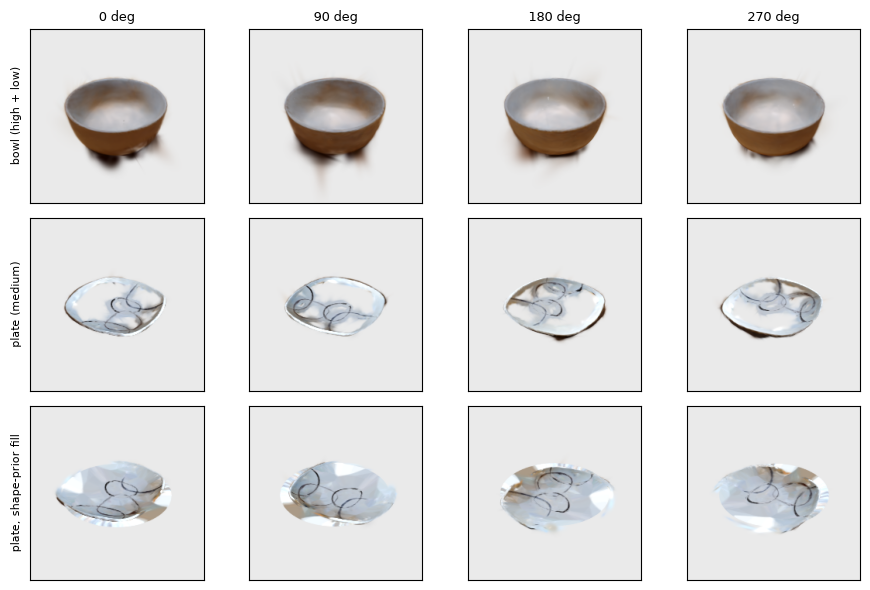

In [12]:
from hurobo.splat import render_splat_orbit
from hurobo.utils.plotting import plot_image_grid

plot_image_grid(
    {
        label: render_splat_orbit(ply, num_views=4, image_size=224, elevation_deg=35)
        for label, ply in {
            "bowl (high + low)": best.bowl_ply,
            "plate (medium)": best.plate_ply,
            "plate, shape-prior fill": best.plate_filled_ply,
        }.items()
    },
    column_titles=["0 deg", "90 deg", "180 deg", "270 deg"],
)

### Against the measurements
These scans have no metric board, so their units are arbitrary and only the height / diameter ratio can be compared with `measurements.yaml`. (The bowl height there is still marked TODO.)

In [13]:
from hurobo.best_scans import scan_vs_measurement
from hurobo.real_setup import RealSetup

scan_vs_measurement(best, RealSetup.load()).set_index("object")

,scan diameter (units),scan height (units),scan height/diameter,real height/diameter,real diameter (cm),metres per scan unit
object,,,,,,
bowl,2.179,0.861,0.395,0.486,13.8,0.063
plate,2.464,0.209,0.085,0.110,25.5,0.104
plate (shape-prior fill),2.168,0.207,0.096,0.110,25.5,0.118


# Part 3: Photoreal real2sim, splats composited into LIBERO

Gaussian splats replace the *appearance* of chosen LIBERO bodies (table, bowl, plate); physics and the robot stay LIBERO's own. The robot mesh and the splats are merged per pixel by depth.

- **Modules:** `hurobo.splat` (`SplatCompositor`, `SplatAsset`, `SplatFit`), `hurobo.sim.LiberoTask`
- **Script version:** `scripts/08_splat_composite.py` (full scripted pick-and-place video)
- **Needs:** a CUDA GPU (gsplat) and EGL; first run may JIT-compile gsplat kernels

The splats here are DISCOVERSE stand-ins, not a scan of our own table, and the motion below is only a teleported bowl, so this shows the *rendering path*, not a policy result.

In [14]:
%%capture
# (capture hides robosuite's startup logging)
from hurobo.sim import LiberoTask
from hurobo.splat import LIBERO_GOAL_DISTRACTOR_ROOTS, SplatCompositor, build_assets
from hurobo.utils.plotting import plot_image_row

task = LiberoTask("libero_goal", 8)
task.reset()
# build_assets: DISCOVERSE pink bowl, white plate and table cloth (downloaded on first use).
compositor = SplatCompositor(
    task.mj_model,
    build_assets(
        bowl_ply="data/splats/dummy_discoverse/object__bowl_pink.ply"
    ),  # object__bowl_pink.ply | dummy_fruit_bowl.ply | bowl.ply
    hidden_body_roots=LIBERO_GOAL_DISTRACTOR_ROOTS,
    width=384,
    height=384,
)

In [15]:
print(f"{compositor.num_gaussians:,} Gaussians attached")

296,764 Gaussians attached


## The four layers
Native LIBERO, the mesh layer (robot and anything not replaced), the splat layer alone, and the depth composite a policy would see.

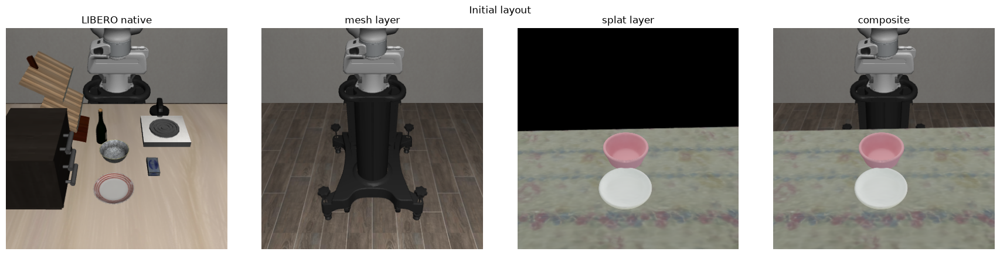

In [16]:
plot_image_row(compositor.render_layers(task.mj_data, "agentview"), "Initial layout")

## Splats follow their bodies
Move the bowl in the simulator; its splat moves with it because it is attached to the body's `xpos`/`xquat` every frame.

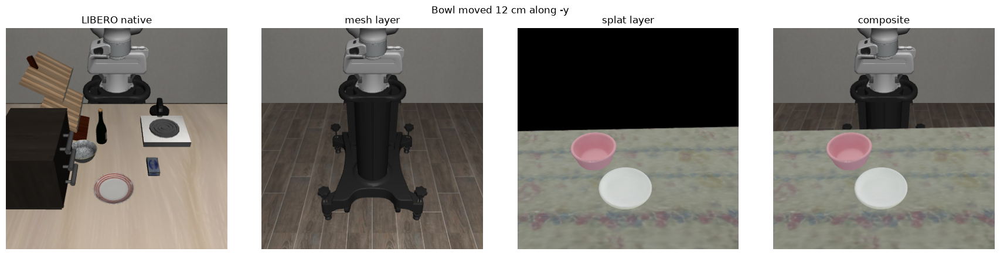

In [17]:
import numpy as np

task.translate_object("akita_black_bowl_1_joint0", np.array([0.0, -0.12, 0.0]))
plot_image_row(compositor.render_layers(task.mj_data, "agentview"), "Bowl moved 12 cm along -y")

## Best scans and DISCOVERSE examples, stock size vs scaled to the real measurements

Four splat sets are attached with `MATCH_BODY_XY`, so a splat takes the size of the body it replaces:

- **DISCOVERSE pink bowl + white plate** and **yellow bowl + green plate**: the stand-ins;
- **best scan**: bowl `bowl_high_low/combined` and plate `plate_med/robust_exhaustive`, and the same with the plate's gaps closed by the shape prior.

Each set is drawn twice. **Stock**: LIBERO's own bodies (its plate is about half the real one). **Scaled**: bodies scaled so the diameters equal `data/raw/setup_01/measurements.yaml` (bowl 13.8 cm, plate 25.5 cm), as in experiment E1. Object positions differ between the two by design: the scaled scene uses our own layout and parks the other objects.

In [18]:
from hurobo.best_scans import BestScans
from hurobo.real_setup import RealSetup
from hurobo.scaled_native import render_unscaled_vs_scaled
from hurobo.splat import DUMMY_SPLAT_DIR, build_assets

best = BestScans()
asset_sets = {
    "DISCOVERSE pink + white": build_assets(),
    "DISCOVERSE yellow + green": build_assets(
        bowl_ply=DUMMY_SPLAT_DIR / "object__yellow_bowl.ply",
        plate_ply=DUMMY_SPLAT_DIR / "object__green_plate.ply",
    ),
    "best scan": build_assets(bowl_ply=best.bowl_ply, plate_ply=best.plate_ply),
    "best scan, filled plate": build_assets(bowl_ply=best.bowl_ply, plate_ply=best.plate_filled_ply),
}
setup = RealSetup.load()
comparison = render_unscaled_vs_scaled(asset_sets, setup, size=320)

Creating LIBERO envs | suites=['libero_goal'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[8]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_goal | task_id=8 | n_envs=1


Creating LIBERO envs | suites=['libero_goal'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[8]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_goal | task_id=8 | n_envs=1


.venv/lib/python3.12/site-packages/robosuite/utils/binding_utils.py:1010: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  self.qpos[addr] = value


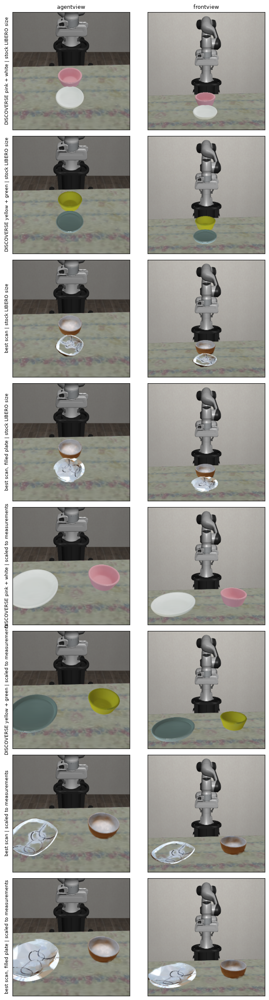

In [19]:
from hurobo.utils.plotting import plot_image_grid

halves = {k: [v[:, : v.shape[1] // 2], v[:, v.shape[1] // 2 :]] for k, v in comparison.items()}
plot_image_grid(halves, column_titles=["agentview", "frontview"], cell_in=3.0)

### Sizes
LIBERO's own diameters against the measured ones and the factor applied. A uniform scale matches the diameter exactly; the height follows from the asset's proportions.

In [20]:
import pandas as pd

from hurobo.scaled_native import ScaledNativeScene

size_scene = ScaledNativeScene(setup)
size_scene.reset()
size_rows = size_scene.scales.comparison(setup)
size_scene.task.close()
pd.DataFrame(size_rows).set_index("object").round(2)

Creating LIBERO envs | suites=['libero_goal'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[8]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_goal | task_id=8 | n_envs=1


,real diameter,LIBERO diameter,scale factor,sim diameter,real height,LIBERO height,sim height
object,,,,,,,
bowl,13.8,11.25,1.23,13.8,6.7,5.26,6.46
plate,25.5,13.75,1.85,25.5,2.8,1.66,3.09


### Reading it
- Stock, the real plate (25.5 cm) is drawn at LIBERO's smaller size, so a scanned plate is shrunk and the bowl sits beside it at almost the same size; scaled, the plate is the large dish it really is next to a 13.8 cm bowl.
- A scan carries its own proportions into the scene: the scanned bowl is flatter than the measured one (see Part 2, height / diameter), and the filled plate shows facets and a prior-shaped rim. The scaling fixes diameters, not shape.
- The scaled layout is not LIBERO's init state, so compare sizes, not positions.

In [21]:
compositor.close()
task.close()